# Collective communication inside one H100 thread-block cluster

On Hopper, the CTAs of a **thread-block cluster** (up to 16 CTAs, each on its own SM of one GPC) can read and write
each other's shared memory directly: **distributed shared memory (DSMEM)**. A collective among the CTAs of one cluster
therefore never touches L2 or HBM: the data moves from SM to SM over the network inside the GPC. Fused LLM kernels
such as ClusterFusion and FlashAttention-4 already exchange data between the CTAs of a cluster this way.

We implemented **29 algorithms for four collectives** (12 allreduce, 7 allgather, 4 reducescatter, 6 alltoall), ports
to DSMEM of algorithms from NCCL, MPICH, TensorRT-LLM, ClusterFusion and other GPU kernels, plus generic patterns. We checked every one for
correctness and timed it at N = 2, 4, 8 and 16 CTAs, with payloads from 256 B per CTA up to the largest that fits in
the 227 KiB of shared memory a CTA can use. The questions are: **which algorithm is fastest for each collective,
cluster size and message size, and why**, explained by the measured properties of the SM-to-SM network.

In [1]:
import collectives_figures as cf
D, F = cf.load(), cf.fabric()

## Setup

In [2]:
cf.table_setup(D)

,value
,
GPU,"NVIDIA H100 NVL (GPU 3, 132 SMs)"
Driver / CUDA runtime,580.126.20 / 12.9
Toolchain,"nvcc 12.9.86, -arch=sm_90a -O3; Nsight Compute..."
SM clock,locked at 1635 MHz (median sample 1635 MHz); m...
Launch,"one cluster of N CTAs, 256 threads per CTA, dy..."
Configurations,"643 (algorithm × N × payload), float"
Timed launches,"257200 (2 sweeps × 200 per configuration, rand..."
Timer,"%globaltimer, 32 ns resolution"


**How time is measured.** Every CTA writes a `%globaltimer` stamp when the collective starts (after a cluster barrier
that follows loading its input into shared memory) and when it ends. The **latency** L of one launch is the time from
the first CTA's start to the last CTA's end. Every value below is the median of 400 launches.

**Payload and bandwidth.** The payload P per CTA uses the data size of nccl-tests:
- allreduce: M·B, the vector each CTA holds;
- allgather: N·M·B, the gathered result;
- reducescatter and alltoall: N·M·B, each CTA's input.

The **bus bandwidth** busbw = (P / L) · f, with f = 2(N−1)/N for allreduce and (N−1)/N for the others, is the rate
at which an algorithm that moves the minimum possible data drives each SM's network port. It can be compared directly
with the port's limit.

**The algorithms**, grouped by how their CTAs synchronise between the start and end stamps. This turns out to be the
deciding property:
- **mbarrier only:** a sender's bulk copy signals the receiver's mbarrier, and only the receiver waits.
- **one exchange + cluster barriers:** one round of remote stores, loads or atomics, published by cluster-wide
  barriers.
- **cluster barrier every round:** a multi-round algorithm in which all CTAs meet at a cluster barrier after each
  round.

| op | algorithm | data pattern | rounds | synchronisation |
|---|---|---|---|---|
| allreduce | two_shot_push | push chunks to their owners (reduce-scatter), push the reduced chunks back (all-gather) | 2 | mbarrier only |
| | 2d_mesh | R×C grid: reduce-scatter along rows, allreduce along columns, all-gather along rows | 3 | mbarrier only |
| | one_shot_pull | every CTA reads every peer's whole vector and reduces | 1 | one exchange + cluster barriers |
| | direct_replicated_push | every CTA stores its vector into every peer, then reduces locally | 1 | one exchange + cluster barriers |
| | pull_reduce_scatter_push_allgather | pull own chunk from all peers, reduce in registers, store it back to all | 1 | one exchange + cluster barriers |
| | atomic_all_push | remote atomic adds into every peer | 1 | one exchange + cluster barriers |
| | ring | ring reduce-scatter then ring all-gather | 2(N−1) | cluster barrier every round |
| | rabenseifner | recursive halving then recursive doubling | 2 log₂N | cluster barrier every round |
| | recursive_doubling | full vector to the CTA at distance 1, 2, 4, … | log₂N | cluster barrier every round |
| | reduce_bcast_binomial | binomial-tree reduce to CTA 0, then broadcast | 2 log₂N | cluster barrier every round |
| | shift_accumulate_bulk | running sum forwarded by shifts (N = 4) | N−2 | cluster barrier every round |
| | shift_accumulate_atomic | shifts with remote atomic adds (N = 2, 4) | N−2 | cluster barrier every round |
| allgather | direct_replicated_push | every CTA stores its block into every peer | 1 | one exchange + cluster barriers |
| | direct_pull | every CTA reads every peer's block | 1 | one exchange + cluster barriers |
| | recursive_doubling | gathered block doubles every round | log₂N | cluster barrier every round |
| | bruck | Bruck: distance doubles every round, final rotation | ⌈log₂N⌉ | cluster barrier every round |
| | ring | forward one block per round | N−1 | cluster barrier every round |
| | direct_shift | own block to the CTA at distance i in round i | N−1 | cluster barrier every round |
| | gather_bcast_binomial | binomial gather to CTA 0, broadcast of the whole result | 2 log₂N | cluster barrier every round |
| reducescatter | direct_push | push chunk j to CTA j | 1 | mbarrier only |
| | direct_pull | read own chunk from every peer | 1 | one exchange + cluster barriers |
| | recursive_halving | exchange halves | log₂N | cluster barrier every round |
| | ring | ring | N−1 | cluster barrier every round |
| alltoall | direct_push | push chunk j to CTA j | 1 | mbarrier only |
| | pairwise_exchange | swap halves (N = 2) | 1 | mbarrier only |
| | direct_pull | read own chunk from every peer | 1 | one exchange + cluster barriers |
| | pairwise_xor | partner = rank ⊕ i in round i | N−1 | cluster barrier every round |
| | shift | partner = rank + i in round i | N−1 | cluster barrier every round |
| | bruck | Bruck: distance doubles, half of the blocks per round | log₂N | cluster barrier every round |

## 1. The network inside a GPC

Before looking at the collectives, here is what the network itself costs. The values come from microbenchmarks on
the same GPU and clock: a single cluster on an otherwise idle chip, dependent chains or ping-pongs between two SMs,
and streams of copies for bandwidth.

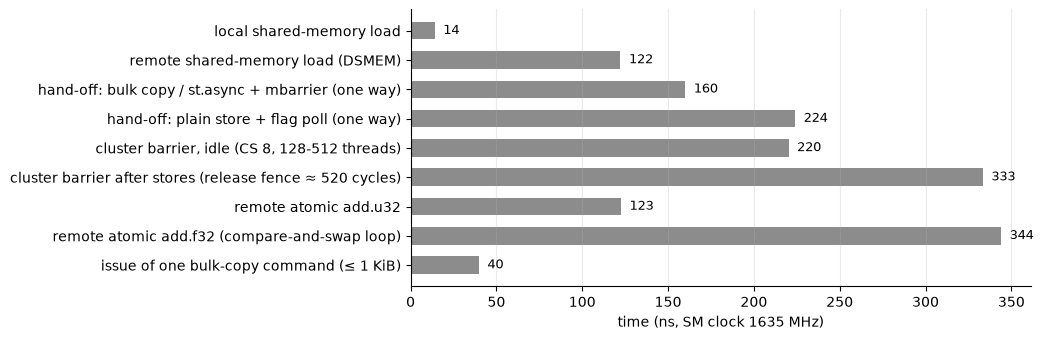

In [3]:
cf.fig_fabric_costs(F)

In [4]:
cf.table_fabric(F)

,cycles,ns,source
primitive,,,
local shared-memory load,23,14,09 k3: 23 cycles
remote shared-memory load (DSMEM),200,122,"09 k1, CS 8"
hand-off: bulk copy / st.async + mbarrier (one way),262,160,09 k2
hand-off: plain store + flag poll (one way),366,224,09 k2
"cluster barrier, idle (CS 8, 128-512 threads)",360,220,07 k2: 360-511 cycles
cluster barrier after stores (release fence ≈ 520 cycles),545,333,07: release behind a store 520-550
remote atomic add.u32,200,123,"12, CS 2"
remote atomic add.f32 (compare-and-swap loop),562,344,"12, CS 2"
issue of one bulk-copy command (≤ 1 KiB),65,40,11: issue-bound at ≈ 65 cycles


Four properties of the network shape everything that follows:

- **A remote access is expensive, and equally expensive everywhere.** A load from another SM's shared memory takes
  ≈ 200 cycles (122 ns), 9× a local load. It takes the same time between any two SMs of a GPC and at every cluster
  size: every request crosses a central hub of the GPC, so there is no "near" neighbour. Mapping ranks to SMs
  cleverly gains nothing; only the *number* of sequential remote steps matters.
- **Signalling another CTA costs ≈ 160 ns, and a cluster barrier more.** The cheapest way to hand data to another
  CTA is a bulk copy or `st.async` that completes the receiver's mbarrier: 160 ns one way. A plain store followed by
  a flag costs 224 ns. A cluster barrier costs 220 ns on an idle cluster, but 333 ns when it must first publish
  earlier stores, which is the case inside every collective. On top of that it waits for *all* N CTAs.
- **Remote float atomics are not native.** An integer remote atomic costs about one remote load (123 ns). A float
  add is compiled into a compare-and-swap loop over the network and costs 344 ns, plus retries when several CTAs
  update the same word.
- **Issuing copies costs time too.** One thread issues a bulk-copy command every ≈ 40 ns, so a thread that pushes to
  N−1 peers waits (N−1) × 40 ns before its last copy leaves.

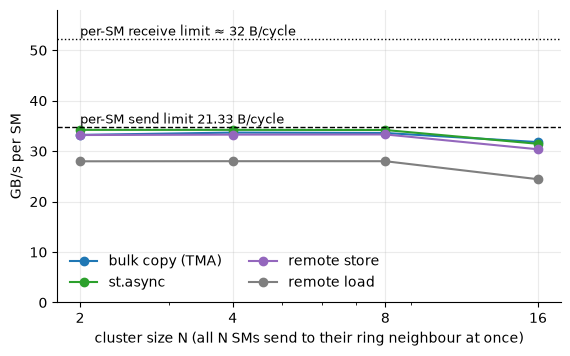

In [5]:
cf.fig_fabric_bandwidth(F)

**Bandwidth.** An SM can send at most **21.33 B/cycle = 34.9 GB/s**, the same for loads, stores, `st.async` and
bulk copies. Crucially, the limit is the same whether it sends to one destination or to 15. It can receive faster
(≈ 32 B/cycle), so the sender side is the bottleneck. When every SM of the cluster sends at once (a ring), each still
gets 33–34 GB/s up to N = 8. At N = 16 the GPC's shared network becomes the limit and each SM gets ≈ 31 GB/s. Remote
*loads* reach less (28 GB/s, 24 at N = 16) because the requests compete with the data.

For collectives this predicts two regimes:
- **Small messages:** cost = number of synchronisations × (160 ns per hand-off or 333 ns per barrier).
- **Large messages:** cost = the bytes the busiest SM must send ÷ 34.9 GB/s.

Because sending to many peers costs no extra bandwidth, a fully connected algorithm should never lose to a ring.
The next sections test these predictions.

## 2. What a small collective costs: counting synchronisations

If the network costs above determine the latency of small collectives, then L ≈ t₀ + (cluster barriers) · t_barrier
+ (mbarrier hand-offs) · t_handoff. Both counts are read from each algorithm's code. Below, the three costs are fitted
to all non-atomic configurations at 256 B per CTA (102 configurations, N = 2–16) and compared with the network
measurements.

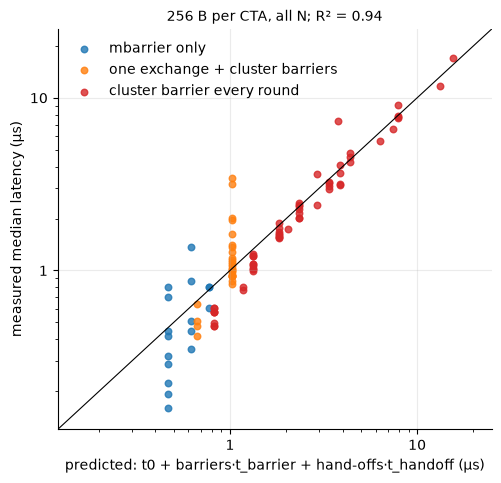

In [6]:
cf.fig_sync_fit(D)

In [7]:
cf.table_sync_fit(D, F)

,fitted on the collectives (ns),measured on the network (ns)
cost,,
fixed cost per collective,311,—
one cluster barrier,355,"220 idle, 333 after stores"
one mbarrier hand-off,154,160


Two counts explain 94 % of the variance in latency across 27 algorithm implementations, four cluster sizes and four
operations, and
**the fitted costs match the network measurements**:
- an mbarrier hand-off costs 154 ns in the collectives against 160 ns measured;
- a cluster barrier costs 355 ns against 333 ns for a barrier that publishes stores.

So a cluster barrier inside a collective costs **2.3 hand-offs**, and that ratio decides the ranking in the next
section. The remaining 311 ns is a fixed cost per collective: stamping, the first proxy fence, mbarrier set-up.

The points far above the line are the two pull algorithms at N = 16 (one-shot pull, reducescatter direct pull) and
two-shot push at N = 16. The code explains both:
- **Pull algorithms:** each thread reads its N peers one after another and uses each value before issuing the next
  load, so it pays N × 122 ns of remote latency in sequence. This is a property of the implementation, not of the
  algorithm; issuing all loads first would hide most of it.
- **Two-shot push:** one thread issues N−1 = 15 copies per phase, 15 × 40 ns.

The points below the line are single-exchange kernels at N = 2, whose fixed cost is smaller than the average.

## 3. Latency: the synchronisation style ranks the algorithms

Median latency at 4 KiB per CTA against cluster size. For each collective, the best algorithm of each
synchronisation style is coloured; all others are grey.

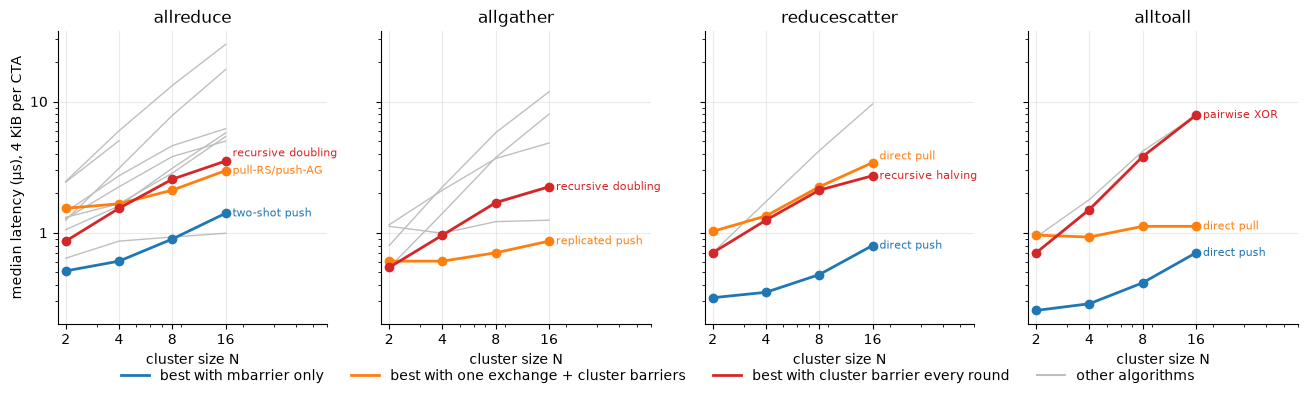

In [8]:
cf.fig_latency_vs_n(D)

For allreduce, reducescatter and alltoall, **the mbarrier-only algorithm is fastest at every cluster size**. At
N = 16 it is 2.5–11× faster than the best algorithm that synchronises every round:

| op | mbarrier only | best with a barrier per round |
|---|---|---|
| allreduce | two-shot 1.41 µs | recursive doubling 3.52 µs (ring 17.5 µs) |
| reducescatter | direct push 0.80 µs | recursive halving 2.72 µs |
| alltoall | direct push 0.70 µs | pairwise XOR 7.9 µs |

The catalogue has no mbarrier-only allgather. There, one round of remote stores published by a barrier (replicated
push, 0.86 µs at N = 16) beats every multi-round algorithm.

Algorithms with a barrier per round grow with their number of rounds, exactly as §2 predicts:
- 2(N−1) rounds for the ring allreduce;
- N−1 for pairwise XOR, shift and the ring reducescatter;
- log₂N for recursive doubling, recursive halving and Bruck.

Among the one-exchange algorithms, the reduce-type pulls (one-shot pull, reducescatter direct pull) grow with N
because each thread reads the N peers one after another (§2). The alltoall direct pull, whose loads are independent,
stays flat at ≈ 1 µs.

Remote atomics are the slowest everywhere (atomic push: 2.5 µs at N = 2, 27 µs at N = 16, at 4 KiB). Each float add
is a compare-and-swap loop over the network, and the N−1 peers that add into the same words make each other retry.

## 4. Bandwidth: how much of the network a collective uses

Bus bandwidth against payload at N = 8 and N = 16, with the per-SM send limit of §1. Coloured: the best algorithm of
each synchronisation style at 64 KiB.

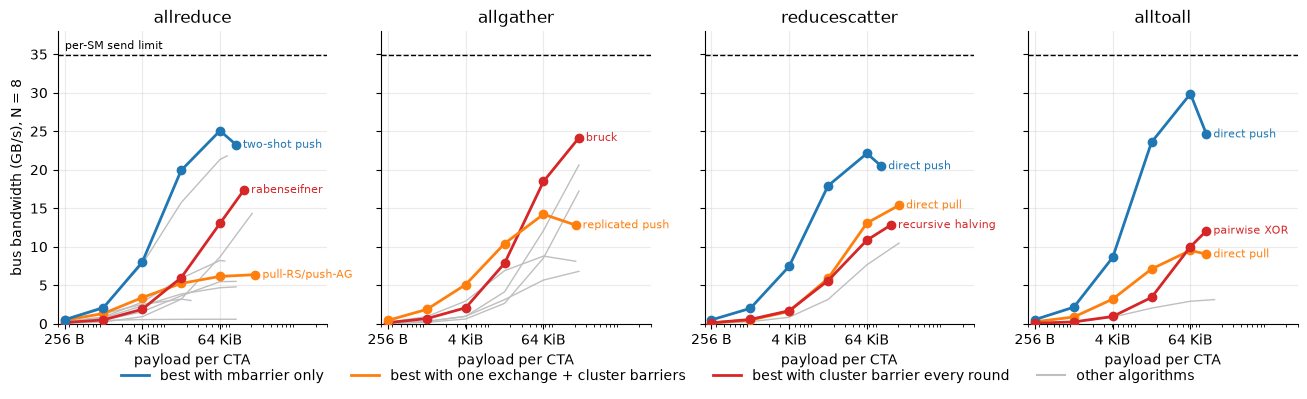

In [9]:
cf.fig_busbw(D, 8)

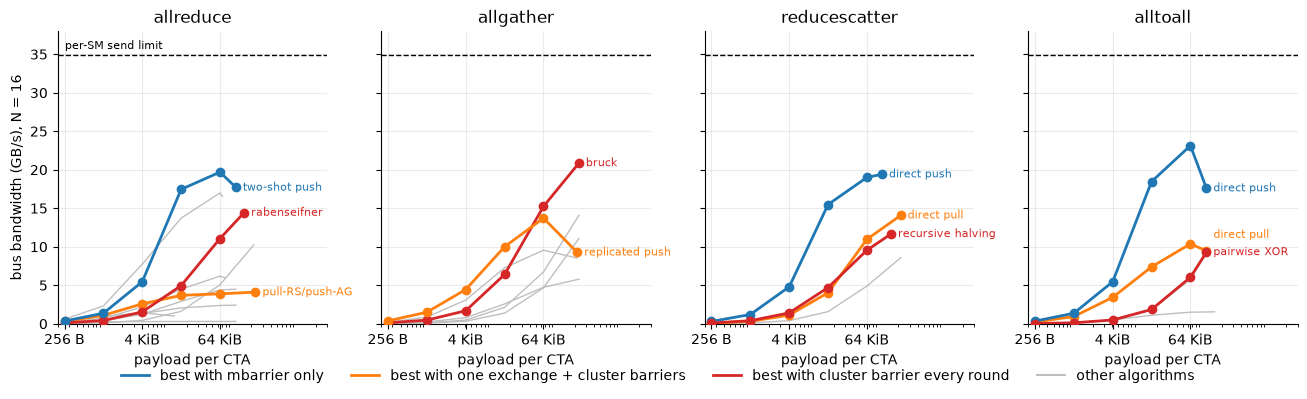

In [10]:
cf.fig_busbw(D, 16)

At N = 8, the best collectives reach **63–86 % of the per-SM send limit** at 64 KiB:
- alltoall direct push 29.9 GB/s;
- allreduce two-shot 25.1 GB/s;
- reducescatter direct push 22.1 GB/s;
- allgather Bruck 24.2 GB/s at its largest payload.

The mbarrier-only pushes get close already at 16 KiB, because their only fixed cost is one or two hand-offs. The
per-round algorithms need much larger messages to amortise ≈ 0.5 µs per round. They approach the pushes only at the
largest payloads, e.g. Bruck allgather (24.2 GB/s at 227 KiB) and Rabenseifner allreduce (17.4 GB/s at 151 KiB).

At N = 16 the same algorithms lose 14–23 % (two-shot 19.7, direct push 23.1 and 19.0 GB/s), which matches the GPC
contention seen in §1 when all 16 SMs send at once.

Two curves stand out:
- **The largest-payload point often drops** (two-shot 25.1 → 23.3 GB/s, alltoall direct push 29.9 → 24.6 GB/s).
  These payloads are not multiples of 128 B, and §6 shows that the network then carries 6–38 % more bytes than the
  payload.
- **pull_reduce_scatter_push_allgather never exceeds 6.4 GB/s.** It moves only the minimum data, but in 4-byte
  accesses that waste most of each network transfer (§6).

## 5. Does the bandwidth-optimal ring ever win?

Between GPUs, NCCL uses the ring for large messages: each GPU sends only 2(N−1)/N·M bytes over its own link, the
minimum. On DSMEM, two-shot push sends exactly the same bytes per CTA, but in 2 exchanges instead of 2(N−1)
synchronised rounds.

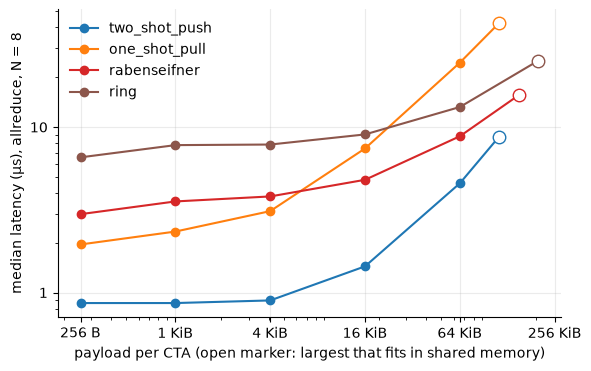

In [11]:
cf.fig_allreduce_ring(D)

At N = 8 two-shot is faster at every payload: 0.9 µs against 7.8 µs at 4 KiB, and 4.6 µs against 13.2 µs at 64 KiB.
The reason is the network property of §1. An SM sends to 7 peers as fast as to one, so the fully connected exchange
loses no bandwidth, while the ring still pays 14 synchronised rounds. Rabenseifner, with 2 log₂N = 6 rounds, sits in
between.

**The ring's only advantage is memory.** It needs M + M/N of shared memory against 2M for two-shot, so it can run
messages up to 206 KiB where two-shot stops at 116 KiB (open markers). On DSMEM the shared-memory footprint, not
bandwidth, is what limits the largest message an algorithm can handle.

One-shot pull, which reads every peer's whole vector (N/2 = 4× the minimum traffic), is faster than the ring up to
16 KiB and loses beyond, as soon as moving data dominates.

## 6. What the hardware counters add

Nsight Compute counts the bytes each SM puts on the DSMEM network. Comparing them with the bytes each algorithm
*must* move (a per-CTA traffic model derived from the code) checks the implementations and shows how the network
accounts for traffic.

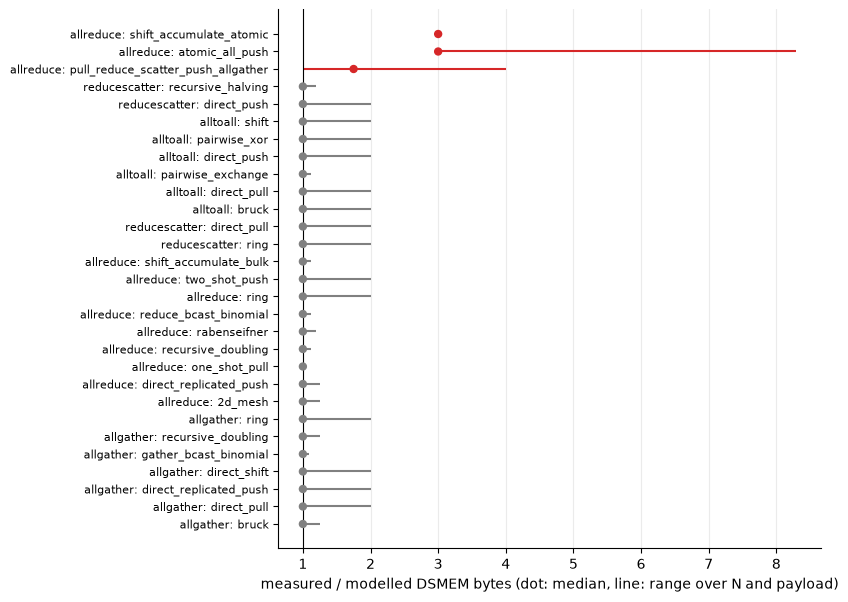

In [12]:
cf.fig_traffic_ratio(D)

**507 of 643 configurations match the model within 10 %, and none is below it.** No implementation moves less than its
algorithm requires. Accesses of a CTA to its own shared memory through the cluster address window are not counted
as network traffic. The deviations are all properties of how the network moves data:

- **Small transfers.** The 25 configurations counted at twice their payload are all at 256 B per CTA with N = 8–16,
  i.e. 16–32 B per message: the network accounts small transfers at more than their size.
- **Lane-interleaved scalar accesses** (pull_reduce_scatter_push_allgather). Consecutive threads address different
  peers, so each warp instruction sends only 128/N bytes to each peer. That is less than a 32-byte sector for N ≥ 8,
  and the counted bytes grow to 2× (N = 8) and 4× (N = 16). This is why its bandwidth stays at 4–6 GB/s (§4): most
  of every transfer is empty.
- **Remote float atomics** (atomic_all_push, shift_accumulate_atomic) count 3× the payload. The compiled code shows
  why: each float add on a peer's shared memory is a 4-byte load followed by an 8-byte compare-and-swap (compare
  value + new value), retried when another CTA got there first.
- **The largest-payload points** of the bulk-copy algorithms (60 of 98) carry 6–38 % extra bytes. Their message sizes
  and offsets are not multiples of 128 B, and their bandwidth drops by a similar amount (§4).

## 7. Conclusions

1. **On DSMEM, small collectives are paid in synchronisations, not in distance or bytes.** A cluster barrier inside
   a collective costs ≈ 355 ns, an mbarrier hand-off ≈ 154 ns, plus ≈ 0.3 µs fixed. These are the network's own
   costs, and remote latency is the same between any two SMs.
2. **Use single-exchange algorithms signalled by mbarriers:** two-shot push or 2D mesh for allreduce, direct push for
   reducescatter and alltoall (pairwise exchange at N = 2). They are the fastest at every cluster size and payload
   measured. For allgather, replicated push wins up to 16 KiB and Bruck above (at N = 2 Bruck from 4 KiB).
3. **Algorithms designed for point-to-point links (ring, pairwise, shift) have no performance advantage here,**
   because an SM sends to N−1 peers as fast as to one. Their only advantage is a smaller shared-memory footprint,
   which allows larger messages.
4. **The best collectives use 63–86 % of the per-SM send limit at N = 8** and lose 14–23 % at N = 16 to contention
   in the GPC.
5. **Avoid what the network handles badly:**
   - remote float atomics, which become compare-and-swap loops;
   - lane-interleaved 4-byte remote accesses, which waste most of each 32-byte sector;
   - dependent sequential remote loads, which cost ≈ 122 ns each;
   - message sizes that are not multiples of 128 B.

**Fastest algorithm per collective, cluster size and payload** (median latency):

In [13]:
cf.table_best(D, "latency")

256 B  \
op            N                                      
allreduce     2            two_shot_push (0.35 µs)   
              4            two_shot_push (0.51 µs)   
              8                   2d_mesh (0.8 µs)   
              16                  2d_mesh (0.8 µs)   
allgather     2   direct_replicated_push (0.42 µs)   
              4   direct_replicated_push (0.48 µs)   
              8   direct_replicated_push (0.51 µs)   
              16  direct_replicated_push (0.64 µs)   
reducescatter 2              direct_push (0.22 µs)   
              4              direct_push (0.32 µs)   
              8              direct_push (0.45 µs)   
              16              direct_push (0.8 µs)   
alltoall      2        pairwise_exchange (0.16 µs)   
              4              direct_push (0.29 µs)   
              8              direct_push (0.42 µs)   
              16              direct_push (0.7 µs)   

                                             1 KiB  \
op            N                                      
allreduce     2            two_shot_push (0.38 µs)   
              4            two_shot_push (0.54 µs)   
              8                   2d_mesh (0.8 µs)   
              16                 2d_mesh (0.83 µs)   
allgather     2   direct_replicated_push (0.45 µs)   
              4   direct_replicated_push (0.42 µs)   
              8   direct_replicated_push (0.48 µs)   
              16  direct_replicated_push (0.64 µs)   
reducescatter 2              direct_push (0.22 µs)   
              4              direct_push (0.32 µs)   
              8              direct_push (0.45 µs)   
              16              direct_push (0.8 µs)   
alltoall      2              direct_push (0.19 µs)   
              4              direct_push (0.29 µs)   
              8              direct_push (0.42 µs)   
              16              direct_push (0.7 µs)   

                                             4 KiB  \
op            N                                      
allreduce     2            two_shot_push (0.51 µs)   
              4            two_shot_push (0.61 µs)   
              8             two_shot_push (0.9 µs)   
              16                 2d_mesh (0.99 µs)   
allgather     2                    bruck (0.54 µs)   
              4   direct_replicated_push (0.61 µs)   
              8    direct_replicated_push (0.7 µs)   
              16  direct_replicated_push (0.86 µs)   
reducescatter 2              direct_push (0.32 µs)   
              4              direct_push (0.35 µs)   
              8              direct_push (0.48 µs)   
              16              direct_push (0.8 µs)   
alltoall      2              direct_push (0.26 µs)   
              4              direct_push (0.29 µs)   
              8              direct_push (0.42 µs)   
              16              direct_push (0.7 µs)   

                                            16 KiB  \
op            N                                      
allreduce     2            two_shot_push (1.09 µs)   
              4            two_shot_push (1.28 µs)   
              8            two_shot_push (1.44 µs)   
              16           two_shot_push (1.76 µs)   
allgather     2                    bruck (0.64 µs)   
              4   direct_replicated_push (1.22 µs)   
              8   direct_replicated_push (1.38 µs)   
              16  direct_replicated_push (1.54 µs)   
reducescatter 2               direct_push (0.7 µs)   
              4              direct_push (0.74 µs)   
              8               direct_push (0.8 µs)   
              16             direct_push (0.99 µs)   
alltoall      2        pairwise_exchange (0.42 µs)   
              4              direct_push (0.51 µs)   
              8              direct_push (0.61 µs)   
              16             direct_push (0.83 µs)   

                                       64 KiB  
op            N                                
allreduce     2       two_shot_push (3.42 µs)  
         

The per-configuration medians and percentiles are in `results/summary_latency.csv` and `results/summary_bandwidth.csv`.

In [14]:
cf.write_summaries(D);